In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn 
import sqlite3

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [2]:
conn = sqlite3.connect('boxscore_ai.db')
df = pd.read_sql("SELECT * FROM games", conn)
conn.close
df.head()

,GAME_ID,TEAM_ID,SEASON_ID,GAME_DATE,TEAM_ABBREVIATION,MATCHUP,WL,PTS,AST,STL,...,FGM,FGA,FG_PCT,FG3M,FG3A,FTM,FTA,OREB,DREB,REB
0,22400062,1610612750,22024,2024-10-22,MIN,MIN @ LAL,L,103,17,4,...,35,85,0.412,13,41,20,27,12,35,47
1,22400062,1610612747,22024,2024-10-22,LAL,LAL vs. MIN,W,110,22,7,...,42,95,0.442,5,30,21,25,15,31,46
2,22400061,1610612738,22024,2024-10-22,BOS,BOS vs. NYK,W,132,33,6,...,48,95,0.505,29,61,7,8,11,29,40
3,22400061,1610612752,22024,2024-10-22,NYK,NYK @ BOS,L,109,20,2,...,43,78,0.551,11,30,12,16,5,29,34
4,22400065,1610612753,22024,2024-10-23,ORL,ORL @ MIA,W,116,28,8,...,41,96,0.427,18,49,16,22,18,39,57


In [3]:
df_copy = df.copy()
df_copy.columns

Index(['GAME_ID', 'TEAM_ID', 'SEASON_ID', 'GAME_DATE', 'TEAM_ABBREVIATION',
       'MATCHUP', 'WL', 'PTS', 'AST', 'STL', 'BLK', 'TOV', 'FGM', 'FGA',
       'FG_PCT', 'FG3M', 'FG3A', 'FTM', 'FTA', 'OREB', 'DREB', 'REB'],
      dtype='object')

In [4]:
df_copy.sort_values("GAME_DATE", ascending=False)

,GAME_ID,TEAM_ID,SEASON_ID,GAME_DATE,TEAM_ABBREVIATION,MATCHUP,WL,PTS,AST,STL,...,FGM,FGA,FG_PCT,FG3M,FG3A,FTM,FTA,OREB,DREB,REB
2459,22401187,1610612738,22024,2025-04-13,BOS,BOS vs. CHA,W,93,22,12,...,35,90,0.389,14,45,9,13,15,34,49
2444,22401187,1610612766,22024,2025-04-13,CHA,CHA @ BOS,L,86,23,10,...,32,85,0.376,11,39,11,18,18,33,51
2430,22401199,1610612757,22024,2025-04-13,POR,POR vs. LAL,W,109,27,7,...,42,96,0.438,15,42,10,21,27,29,56
2431,22401190,1610612764,22024,2025-04-13,WAS,WAS @ MIA,W,119,33,4,...,46,90,0.511,16,37,11,17,6,37,43
2432,22401192,1610612765,22024,2025-04-13,DET,DET @ MIL,L,133,35,9,...,51,107,0.477,22,59,9,14,14,28,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4,22400065,1610612753,22024,2024-10-23,ORL,ORL @ MIA,W,116,28,8,...,41,96,0.427,18,49,16,22,18,39,57
2,22400061,1610612738,22024,2024-10-22,BOS,BOS vs. NYK,W,132,33,6,...,48,95,0.505,29,61,7,8,11,29,40
1,22400062,1610612747,22024,2024-10-22,LAL,LAL vs. MIN,W,110,22,7,...,42,95,0.442,5,30,21,25,15,31,46
3,22400061,1610612752,22024,2024-10-22,NYK,NYK @ BOS,L,109,20,2,...,43,78,0.551,11,30,12,16,5,29,34


In [ ]:
df_copy['FG2M'] = df_copy['FGM'] - df_copy['FG3M']  # separates the stats of perimeter/2-pt shots and 3-pts to identify playstyle of teams
playstyle_cols = ["AST", "BLK", "FG2M", "FG3M", "OREB"]  # features

team_tendencies = df_copy.groupby(["TEAM_ABBREVIATION", "SEASON_ID"])[playstyle_cols].agg("mean").reset_index() # league average to compare to
team_tendencies.head()

,TEAM_ABBREVIATION,SEASON_ID,AST,BLK,FG2M,FG3M,OREB
0,ATL,22024,29.585366,5.109756,29.865854,13.500000,11.878049
1,BKN,22024,25.158537,4.292683,24.060976,13.573171,10.902439
2,BOS,22024,26.146341,5.512195,23.853659,17.768293,11.378049
3,CHA,22024,24.317073,4.487805,25.329268,12.987805,12.231707
4,CHI,22024,29.060976,4.707317,27.768293,15.439024,10.060976


#### Scale the dataset first so there's no massive distances between data points

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(team_tendencies[playstyle_cols])

#### Elbow method - choosing optimal number of cluster

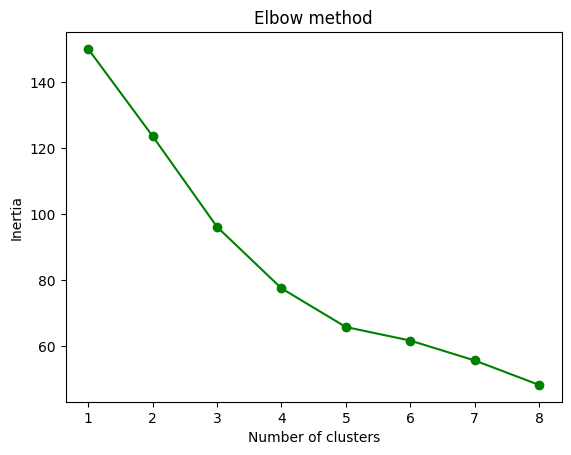

In [7]:
from sklearn.cluster import KMeans

inertias = []
ks = range(1, 9)

for k in ks:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.plot(ks, inertias, color='green', marker='o')
plt.title("Elbow method")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42)  # 5 is the optimal number of k
team_tendencies['cluster'] = kmeans.fit_predict(X_scaled) 
team_tendencies.head()

,TEAM_ABBREVIATION,SEASON_ID,AST,BLK,FG2M,FG3M,OREB,cluster
0,ATL,22024,29.585366,5.109756,29.865854,13.500000,11.878049,4
1,BKN,22024,25.158537,4.292683,24.060976,13.573171,10.902439,1
2,BOS,22024,26.146341,5.512195,23.853659,17.768293,11.378049,2
3,CHA,22024,24.317073,4.487805,25.329268,12.987805,12.231707,1
4,CHI,22024,29.060976,4.707317,27.768293,15.439024,10.060976,2


In [9]:
cluster_profiles_avg = team_tendencies.groupby('cluster')[playstyle_cols].mean()
cluster_profiles_avg

,AST,BLK,FG2M,FG3M,OREB
cluster,,,,,
0,28.243902,5.560976,29.386179,13.947154,10.239837
1,25.149051,4.472900,26.708672,13.329268,10.439024
2,27.715447,4.831301,26.414634,15.648374,10.965447
3,24.607724,5.359756,28.747967,12.343496,12.115854
4,28.579268,4.699187,30.857724,12.731707,11.735772


In [ ]:
league_avg = team_tendencies[playstyle_cols].mean()
relative_diff = cluster_profiles_avg - league_avg   # know which teams are excelling to a certain stat by comparing to the savg tats of the whole league
relative_diff.round(2)

,AST,BLK,FG2M,FG3M,OREB
cluster,,,,,
0,1.69,0.68,1.23,0.41,-0.88
1,-1.40,-0.40,-1.45,-0.21,-0.68
2,1.17,-0.04,-1.74,2.11,-0.15
3,-1.94,0.48,0.59,-1.19,1.00
4,2.03,-0.18,2.70,-0.81,0.62


### Interpretation:

##### Cluster 0 - Defensive/Balanced Teams:
- seeing the OREB, these are teams that abandon the offensive glass as soon as the team misses a shot and goes straightly to defensive to avoid easy opponent fastbreaks
- these teams have also above average assists meaning they rotate the ball well leading to a score
- they have the highest block averages which means they're good defensive teams as well
- they're more of a perimeter/inside scoring teams rather than 3-pt shooting teams but they're slightly above average for 3 pt shooting so they're pretty balanced

#### Cluster 1 - Rebuilding/Tanking Teams:
- these teams are below the league's averages when it comes to assists neither the blocks, midrange/perimeter, 3-pt made shots, and has low offensive rebounds too
- these teams are most likely the rebuilding/tanking teams that are preparing for a draft

#### Cluster 2 - Shooter Teams:
- These teams have above the league's average when it comes to assists which means they're converting their high 3 pt field goals
- teams that are relying heavily to 3-pt field goals are in this chapter (ex: Boston Celtics and Golden State Warriors)
- they're likely going back to defense after a missed shot to prevent an opponnt's fastbreak opportunity

#### Cluster 3 - Isolation Teams:
- these teams aren't hhaving good ball movement because probably theyr're relying more on Isolations plays which i think is more on perimeter not behind the 3 pt line
- they're slightly above the league's average when it comes to blocks 
- they're mmore of a perimeter/midgrange shooter and the field goal 3
- they take offensive boards that are often key to second chance points     

#### Cluster 4 - Team play/Perimeter Specialists Teams:
- These teams have the highest assists stats which basically means they run the offense great and they take most of their shots in midrange/perimeter
- They decent good defense as well as they're just slightly below the league's average
- They don't have good shooters on behind the 3 pt line though
- They take second changes as well often times because of t heir above average offensive rebounds                                                       